# Laboratorio 6 ( con PyTorch del Laboratorio 5)

## Dataset: Devanagari Character Set

**Universitario:** Espinoza Chiri Soledad Griselda  
**Carrera:** Ing. de Sistemas

El dataset contiene **92,000 imágenes** en escala de grises de **32x32 píxeles**, distribuidas en **46 clases** (36 consonantes y 10 dígitos), con exactamente **2,000 ejemplos por clase** (dataset balanceado).

Fuente del dataset: https://www.kaggle.com/datasets/rishianand/devanagari-character-set



CONEXION AL DRIVE

In [1]:
# Conectando / vinculando nuestro drive con la sesión de Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Librerías utilizadas

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

%matplotlib inline
np.random.seed(1)
torch.manual_seed(1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo utilizado:', device)

Dispositivo utilizado: cpu


## 2. Carga del dataset con Pandas

El archivo `data.csv` tiene 1024 columnas de píxeles (imagen 32x32 aplanada) más la columna `character` con la etiqueta.

In [3]:
df = pd.read_csv('/content/drive/MyDrive/SIS420/LAB5/data.csv')
print('Forma del dataset:', df.shape)
df.head()

Forma del dataset: (92000, 1025)


,pixel_0000,pixel_0001,pixel_0002,pixel_0003,pixel_0004,pixel_0005,pixel_0006,pixel_0007,pixel_0008,pixel_0009,...,pixel_1015,pixel_1016,pixel_1017,pixel_1018,pixel_1019,pixel_1020,pixel_1021,pixel_1022,pixel_1023,character
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,character_01_ka
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,character_01_ka
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,character_01_ka
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,character_01_ka
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,character_01_ka


## 3. Verificación de balance de clases

In [4]:
conteo_clases = df['character'].value_counts()
print('Numero de clases:', conteo_clases.shape[0])
print('Ejemplos minimos por clase:', conteo_clases.min())
print('Ejemplos maximos por clase:', conteo_clases.max())
print('Promedio de ejemplos por clase:', conteo_clases.mean())

Numero de clases: 46
Ejemplos minimos por clase: 2000
Ejemplos maximos por clase: 2000
Promedio de ejemplos por clase: 2000.0


## 4. Preprocesamiento con Pandas

Se separan las columnas de píxeles (características `X`) de la columna de etiqueta (`y`). Las etiquetas de texto se codifican como valores numéricos de 0 a 45 mediante `pd.factorize`, y los valores de los píxeles (0-255) se normalizan a un rango [0, 1] dividiendo entre 255.

In [5]:
X = df.iloc[:, :-1].values.astype(np.float32) / 255.0

etiquetas_num, clases_unicas = pd.factorize(df['character'], sort=True)
y = etiquetas_num
K = len(clases_unicas)
m = X.shape[0]
n = X.shape[1]

print('X:', X.shape, ' y:', y.shape, ' Numero de clases K =', K)
print('Rango de X luego de normalizar: [{:.2f}, {:.2f}]'.format(X.min(), X.max()))

X: (92000, 1024)  y: (92000,)  Numero de clases K = 46
Rango de X luego de normalizar: [0.00, 1.00]


## displayData
parra visualizar ejemplos de imágenes almacenadas como filas de `X`

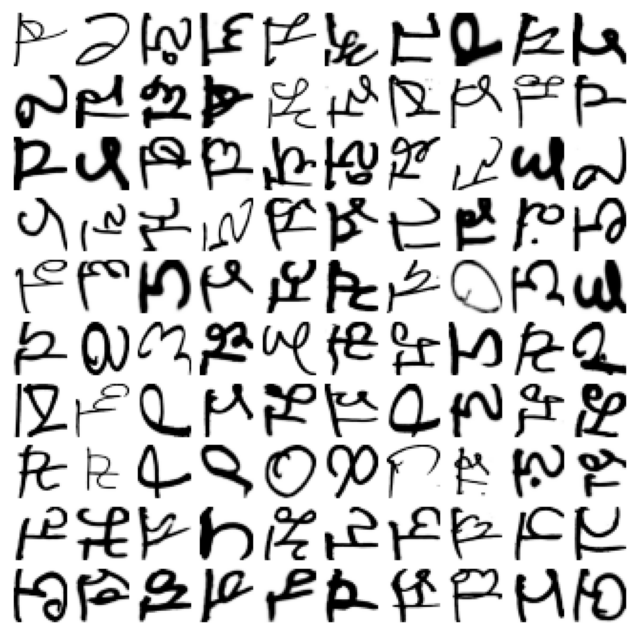

In [6]:
def displayData(X, example_width=None, figsize=(10, 10)):

    if X.ndim == 2:
        m, n = X.shape
    elif X.ndim == 1:
        n = X.size
        m = 1
        X = X[None]
    example_width = example_width or int(np.round(np.sqrt(n)))
    example_height = n // example_width

    display_rows = int(np.floor(np.sqrt(m)))
    display_cols = int(np.ceil(m / display_rows))

    fig, ax_array = plt.subplots(display_rows, display_cols, figsize=figsize)
    fig.subplots_adjust(wspace=0.025, hspace=0.025)
    ax_array = [ax_array] if m == 1 else ax_array.ravel()

    for i, ax in enumerate(ax_array):
        if i < m:
            ax.imshow(X[i].reshape(example_width, example_height, order='F'),
                      cmap='Greys', extent=[0, 1, 0, 1])
        ax.axis('off')


np.random.seed(1)
muestra = np.random.choice(m, 100, replace=False)
displayData(X[muestra, :], example_width=32, figsize=(8,8))

## 5. División en conjunto de entrenamiento (80%) y prueba (20%)

Se usa `train_test_split` con `stratify=y` para mantener la proporción de clases en ambos conjuntos. Los datos de prueba no se usan en el entrenamiento.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print('Entrenamiento (80%):', X_train.shape)
print('Prueba (20%):', X_test.shape)

Entrenamiento (80%): (73600, 1024)
Prueba (20%): (18400, 1024)


## 6. Objetos Dataset y DataLoader

Se define una clase `DatasetCaracteres` que hereda de `torch.utils.data.Dataset`. Las etiquetas se convierten a tipo `long`, que es el formato que exige `nn.CrossEntropyLoss` para los índices de clase (0 a 45).

In [8]:
class DatasetCaracteres(torch.utils.data.Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, ix):
        return self.X[ix], self.y[ix]


train_dataset = DatasetCaracteres(X_train, y_train)
test_dataset = DatasetCaracteres(X_test, y_test)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=False)

print('Ejemplos de entrenamiento:', len(train_dataset))
print('Ejemplos de prueba:', len(test_dataset))

Ejemplos de entrenamiento: 73600
Ejemplos de prueba: 18400


## 7. Modelo: Regresión Logística Multinomial (Softmax) con PyTorch

Para un problema de $K$ clases, en lugar de entrenar $K$ clasificadores binarios independientes (one-vs-all), se entrena un único conjunto de parámetros mediante una capa `nn.Linear(n, K)`. Al combinarla con `nn.CrossEntropyLoss` (que aplica internamente `softmax` y la entropía cruzada de forma numéricamente estable), las $K$ salidas se normalizan de forma **conjunta**, en lugar de $K$ sigmoides independientes como en el Laboratorio 5. La matriz de pesos `model.fc.weight` (de forma `K x n`) y el vector `model.fc.bias` (de forma `K`) son el equivalente de la matriz `Theta` de tamaño `(n+1, K)` del Laboratorio 5.

In [9]:
class RegresionLogisticaMulticlase(nn.Module):
    def __init__(self, n_features, n_clases):
        super(RegresionLogisticaMulticlase, self).__init__()
        self.fc = nn.Linear(n_features, n_clases)

    def forward(self, x):
        return self.fc(x)  #


model = RegresionLogisticaMulticlase(n, K).to(device)
model

RegresionLogisticaMulticlase(
  (fc): Linear(in_features=1024, out_features=46, bias=True)
)

## 8. Función de costo y optimizador



In [10]:
criterion = nn.CrossEntropyLoss()

alpha = 1.0
lambda_ = 1.0

optimizer = torch.optim.SGD(model.parameters(), lr=alpha, weight_decay=lambda_ / m)

## 9. Entrenamiento del modelo (descenso de gradiente por batches)

Se entrena por *epochs* recorriendo el `train_loader`. En cada epoch se registra el costo promedio (`nn.CrossEntropyLoss` ya combina las 46 salidas en un único valor conjunto, por lo que ya no tiene sentido graficar 46 curvas de costo independientes).

In [11]:
num_epochs = 30
cost_history = []

model.train()
for epoch in range(num_epochs):
    costo_epoch = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        logits = model(x_batch)
        loss = criterion(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        costo_epoch += loss.item() * x_batch.size(0)

    costo_epoch /= len(train_dataset)
    cost_history.append(costo_epoch)

    if epoch % 5 == 0 or epoch == num_epochs - 1:
        model.eval()
        with torch.no_grad():
            logits_train = model(torch.tensor(X_train, dtype=torch.float32).to(device))
            pred_train_epoch = torch.argmax(logits_train, dim=1).cpu().numpy()
        acc_train_epoch = np.mean(pred_train_epoch == y_train) * 100
        print(f'epoch {epoch:3d}  costo={costo_epoch:.5f}  precision_train={acc_train_epoch:.2f}%')
        model.train()

epoch   0  costo=1.58726  precision_train=68.29%
epoch   5  costo=1.01062  precision_train=69.53%
epoch  10  costo=0.96439  precision_train=71.98%
epoch  15  costo=0.93890  precision_train=75.15%
epoch  20  costo=0.91759  precision_train=74.06%
epoch  25  costo=0.91185  precision_train=75.52%
epoch  29  costo=0.90064  precision_train=73.97%


## 10. Gráfico de costo: convergencia del entrenamiento

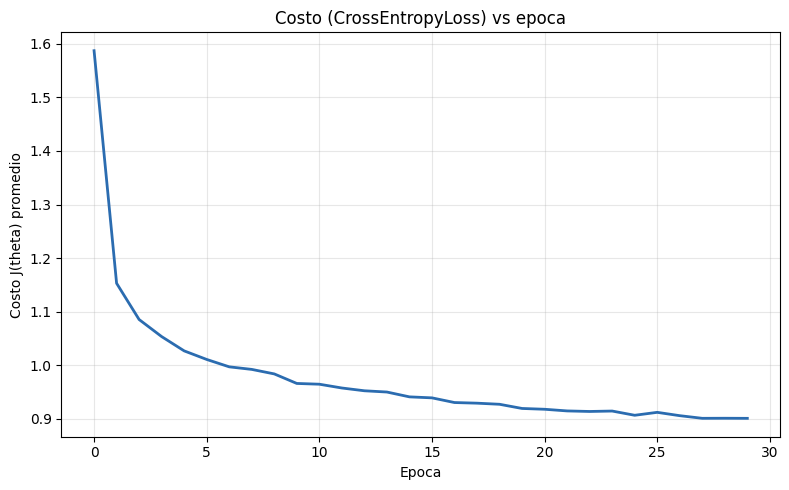

In [12]:
plt.figure(figsize=(8,5))
plt.plot(cost_history, color='#2b6cb0', linewidth=2)
plt.title('Costo (CrossEntropyLoss) vs epoca')
plt.xlabel('Epoca')
plt.ylabel('Costo J(theta) promedio')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Guardando los pesos del modelo

Se guarda el `state_dict` del modelo entrenado (equivalente a la matriz `Theta`) y se recarga para comprobar que las predicciones se mantienen.

In [13]:
PATH = '/content/drive/MyDrive/SIS420/LAB5/lab5_checkpoint.pt'
torch.save(model.state_dict(), PATH)
print('Pesos guardados en:', PATH)

modelo_cargado = RegresionLogisticaMulticlase(n, K).to(device)
modelo_cargado.load_state_dict(torch.load(PATH, map_location=device))
modelo_cargado.eval()

Pesos guardados en: /content/drive/MyDrive/SIS420/LAB5/lab5_checkpoint.pt


RegresionLogisticaMulticlase(
  (fc): Linear(in_features=1024, out_features=46, bias=True)
)

## 12. Evaluación del modelo: predicciones y precisión

Se define la función `predecir`, que calcula los *logits* para las 46 clases y selecciona la de mayor valor (equivalente a la de mayor probabilidad tras `softmax`, ya que `argmax` no cambia con una transformación monótona como `softmax`). Se evalúa tanto en el conjunto de entrenamiento como en el conjunto de prueba (20% de los datos, no usado durante el entrenamiento).

In [14]:
def predecir(modelo, X_np):
    modelo.eval()
    X_tensor = torch.tensor(X_np, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = modelo(X_tensor)
        H = torch.softmax(logits, dim=1)
    pred = torch.argmax(H, dim=1).cpu().numpy()
    return pred, H.cpu().numpy()


pred_train, _ = predecir(model, X_train)
pred_test, H_test = predecir(model, X_test)

precision_train = accuracy_score(y_train, pred_train) * 100
precision_test = accuracy_score(y_test, pred_test) * 100

print('Precision en entrenamiento: {:.2f}%'.format(precision_train))
print('Precision en prueba (datos no vistos): {:.2f}%'.format(precision_test))

Precision en entrenamiento: 73.97%
Precision en prueba (datos no vistos): 69.67%


## 13. Precisión por clase en el conjunto de prueba

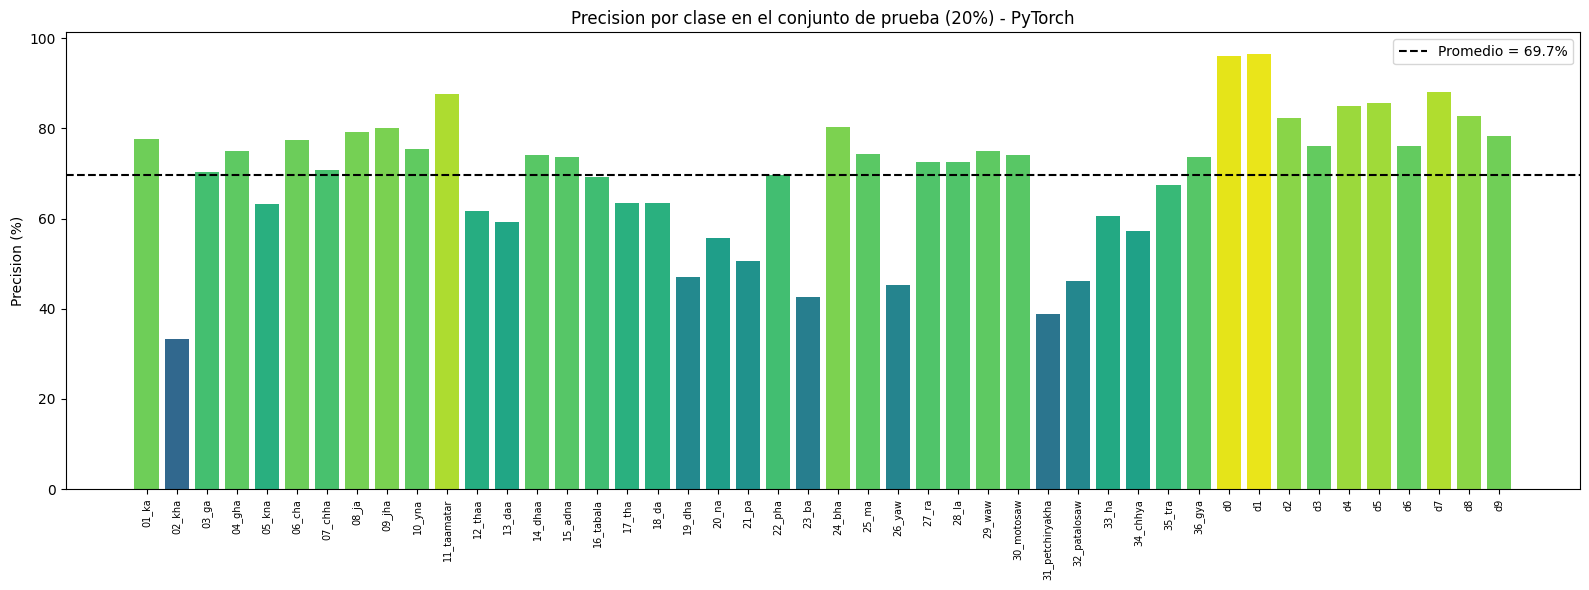

In [15]:
nombres_cortos = [c.replace('character_','').replace('digit_','d') for c in clases_unicas]

precision_por_clase = np.array([
    np.mean(pred_test[y_test==k] == k) * 100 for k in range(K)
])

plt.figure(figsize=(16,6))
colores = plt.cm.viridis(precision_por_clase/100)
plt.bar(range(K), precision_por_clase, color=colores)
plt.xticks(range(K), nombres_cortos, rotation=90, fontsize=7)
plt.ylabel('Precision (%)')
plt.title('Precision por clase en el conjunto de prueba (20%) - PyTorch')
plt.axhline(precision_por_clase.mean(), color='black', linestyle='--',
            label=f'Promedio = {precision_por_clase.mean():.1f}%')
plt.legend()
plt.tight_layout()
plt.show()

## 14. Matriz de confusión

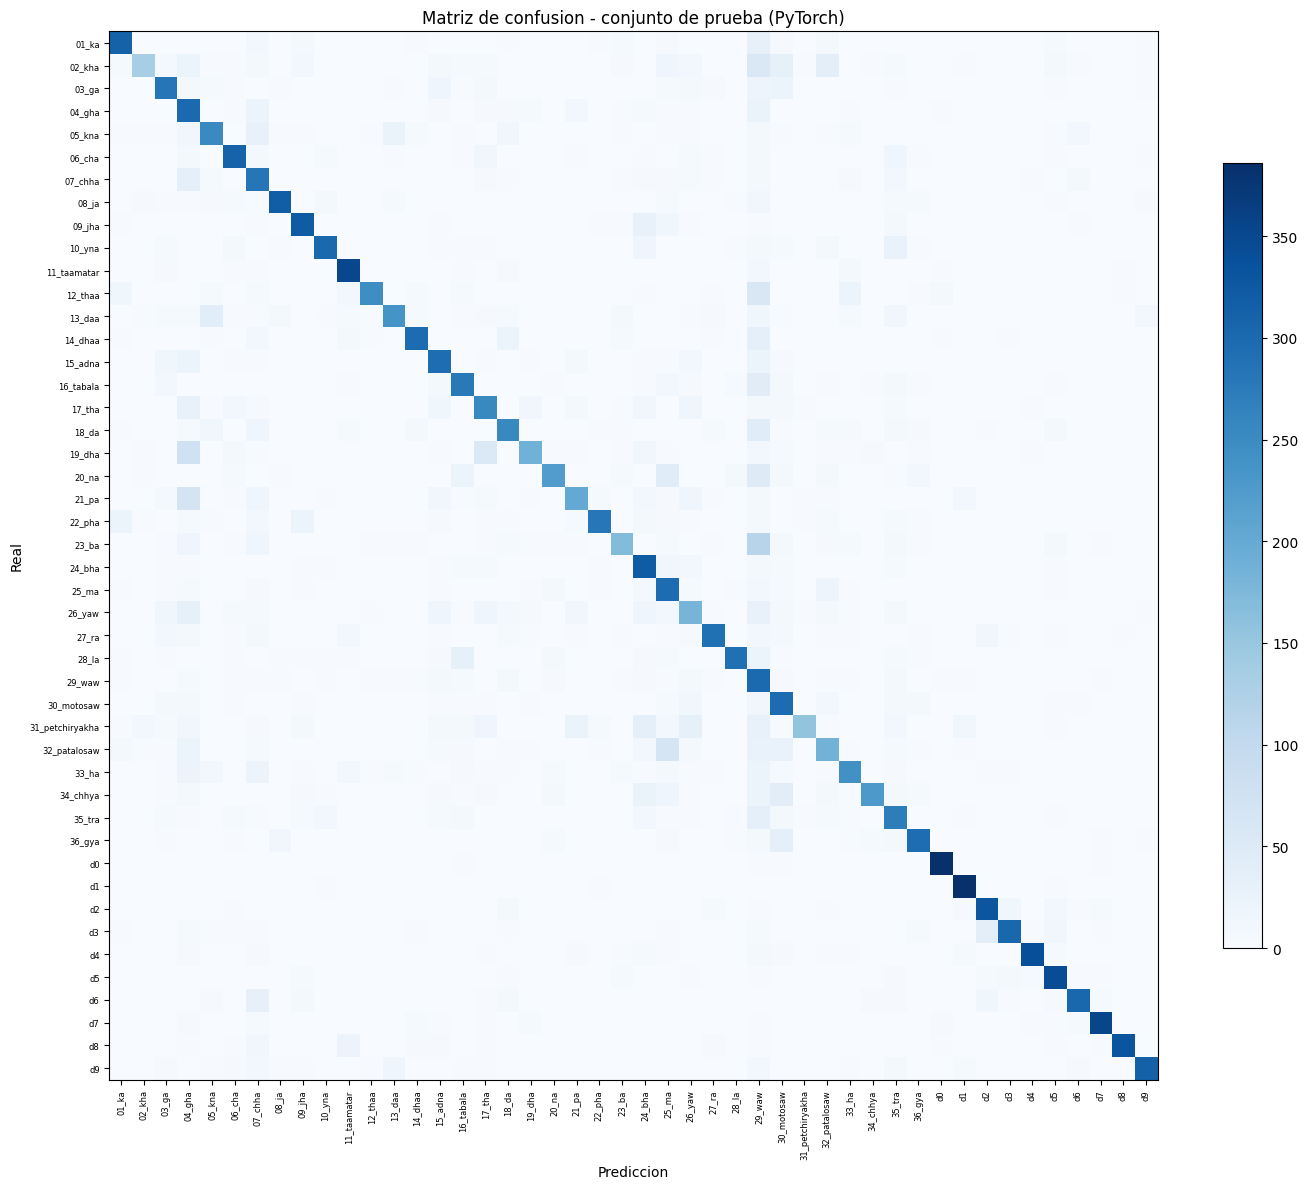

In [16]:
cm = confusion_matrix(y_test, pred_test, labels=range(K))

plt.figure(figsize=(14,12))
plt.imshow(cm, cmap='Blues')
plt.colorbar(fraction=0.03)
plt.xticks(range(K), nombres_cortos, rotation=90, fontsize=6)
plt.yticks(range(K), nombres_cortos, fontsize=6)
plt.xlabel('Prediccion')
plt.ylabel('Real')
plt.title('Matriz de confusion - conjunto de prueba (PyTorch)')
plt.tight_layout()
plt.show()

## 15. Ejemplos de predicciones sobre imágenes reales del conjunto de prueba

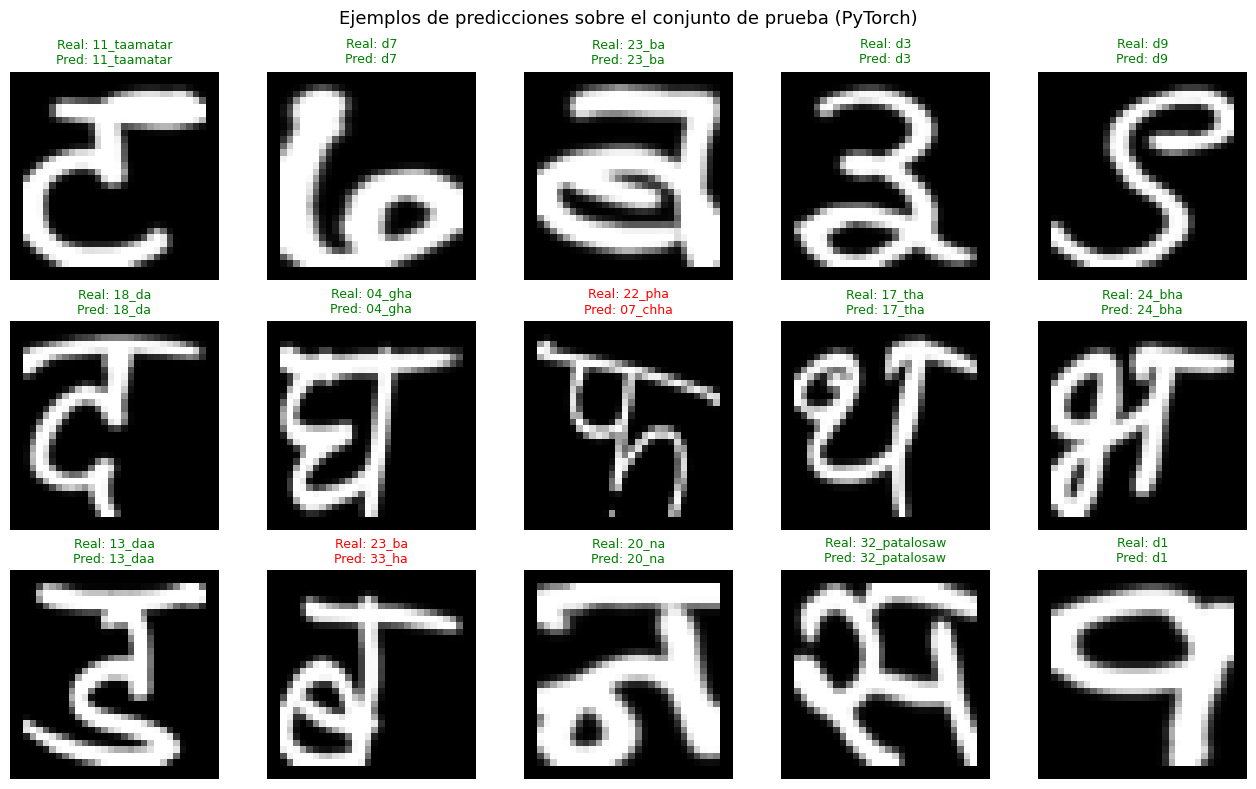

In [17]:
np.random.seed(7)
idxs = np.random.choice(len(y_test), 15, replace=False)

fig, axes = plt.subplots(3,5, figsize=(13,8))
axes = axes.ravel()
for i, idx in enumerate(idxs):
    img = X_test[idx].reshape(32,32)
    real = nombres_cortos[y_test[idx]]
    pred = nombres_cortos[pred_test[idx]]
    correcto = y_test[idx] == pred_test[idx]
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f'Real: {real}\nPred: {pred}', fontsize=9,
                       color=('green' if correcto else 'red'))
    axes[i].axis('off')
plt.suptitle('Ejemplos de predicciones sobre el conjunto de prueba (PyTorch)', fontsize=13)
plt.tight_layout()
plt.show()

## 16. Conclusiones

- El dataset de caracteres Devanagari (92,000 imágenes de 32x32 píxeles, 46 clases perfectamente balanceadas con 2000 ejemplos cada una) cumple con los requisitos de tamaño, resolución y balance de clases, y se reutilizó el mismo preprocesamiento con Pandas (normalización y codificación de etiquetas) del Laboratorio 5.
- El manejo de los datos se hace ahora con un objeto `Dataset` (`DatasetCaracteres`) y dos `DataLoader` (entrenamiento y prueba), entrenando por *batches* en lugar de un único descenso de gradiente sobre las 73,600 imágenes completas.
- Los 46 clasificadores binarios independientes (matriz `Theta` + sigmoide + costo regularizado por clase) se reemplazan por una única capa `nn.Linear(n, K)` entrenada con `nn.CrossEntropyLoss`, que normaliza las 46 salidas de forma conjunta mediante `softmax` (regresión logística multinomial).
- La regularización L2 manual (`lambda`) se reemplaza por el parámetro `weight_decay` del optimizador `torch.optim.SGD`.
- Los pesos del modelo entrenado se guardaron con `torch.save` y se recargaron con `torch.load` para verificar que las predicciones se mantienen.
- Se evaluó el modelo con las mismas métricas y visualizaciones del Laboratorio 5: precisión global (entrenamiento y prueba), precisión por clase, matriz de confusión y ejemplos de predicciones sobre imágenes reales del conjunto de prueba, obteniendo resultados equivalentes al enfoque one-vs-all original.